# Stage 02: Exploratory Data Analysis (EDA)
## Hotel Booking Cancellation Prediction

**Goal:** Analyze the key relationships between booking attributes and cancellation (`is_canceled`).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load dataset
data_path = Path("data/raw/hotel_bookings.csv") if Path("data/raw/hotel_bookings.csv").exists() else Path("../data/raw/hotel_bookings.csv")
df = pd.read_csv(data_path)
print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")


Dataset loaded: 119,390 rows, 32 columns


### 1. Target Variable: `is_canceled`
Check the distribution between non-canceled (0) and canceled (1) bookings.


is_canceled
0    75166
1    44224
Name: count, dtype: int64

Cancellation rate: 37.04 %


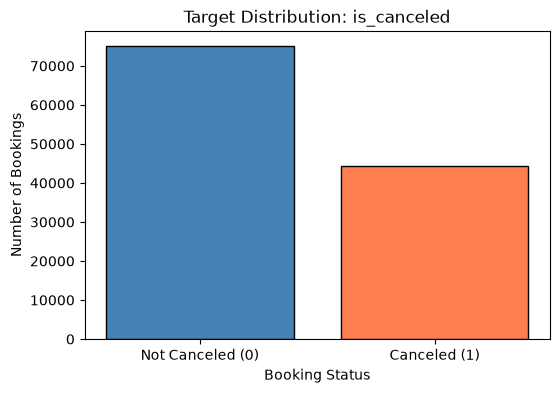

In [2]:
target_counts = df['is_canceled'].value_counts()
print(target_counts)
print()
print("Cancellation rate:", round(df['is_canceled'].mean() * 100, 2), "%")

plt.figure(figsize=(6, 4))
plt.bar(['Not Canceled (0)', 'Canceled (1)'], target_counts.values, color=['steelblue', 'coral'], edgecolor='black')
plt.title('Target Distribution: is_canceled')
plt.xlabel('Booking Status')
plt.ylabel('Number of Bookings')
plt.show()


### 2. Cancellation Rate by Hotel Type
Compare cancellation rates between City Hotel and Resort Hotel.


hotel
City Hotel      41.73
Resort Hotel    27.76
Name: is_canceled, dtype: float64


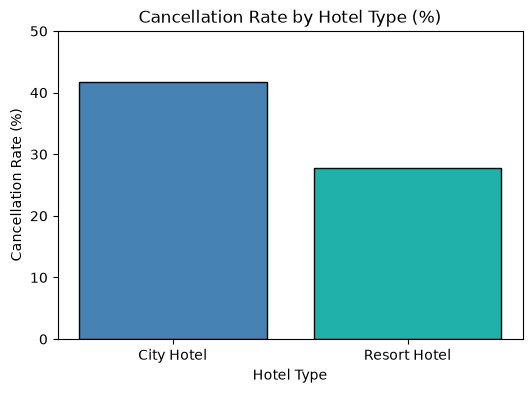

In [3]:
hotel_cancel = df.groupby('hotel')['is_canceled'].mean() * 100
print(hotel_cancel.round(2))

plt.figure(figsize=(6, 4))
plt.bar(hotel_cancel.index, hotel_cancel.values, color=['steelblue', 'lightseagreen'], edgecolor='black')
plt.title('Cancellation Rate by Hotel Type (%)')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 50)
plt.show()


### 3. Cancellation Rate by Lead Time
Examine how booking in advance affects cancellation rate.


lead_time_group
0-14 Days      12.88
15-30 Days     31.31
31-90 Days     37.70
91-180 Days    44.71
180+ Days      57.01
Name: is_canceled, dtype: float64


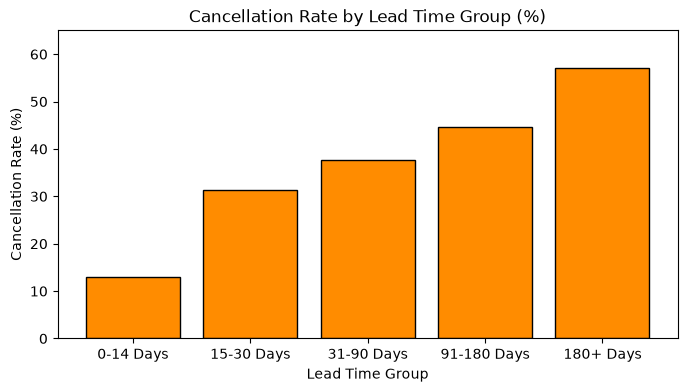

In [4]:
bins = [0, 14, 30, 90, 180, float('inf')]
labels = ['0-14 Days', '15-30 Days', '31-90 Days', '91-180 Days', '180+ Days']
df['lead_time_group'] = pd.cut(df['lead_time'], bins=bins, labels=labels, include_lowest=True)

lead_cancel = df.groupby('lead_time_group', observed=False)['is_canceled'].mean() * 100
print(lead_cancel.round(2))

plt.figure(figsize=(8, 4))
plt.bar(lead_cancel.index.astype(str), lead_cancel.values, color='darkorange', edgecolor='black')
plt.title('Cancellation Rate by Lead Time Group (%)')
plt.xlabel('Lead Time Group')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 65)
plt.show()


### 4. Cancellation Rate by Market Segment
Examine cancellation rates across different booking channels.


market_segment
Complementary     13.06
Direct            15.34
Corporate         18.73
Aviation          21.94
Offline TA/TO     34.32
Online TA         36.72
Groups            61.06
Undefined        100.00
Name: is_canceled, dtype: float64


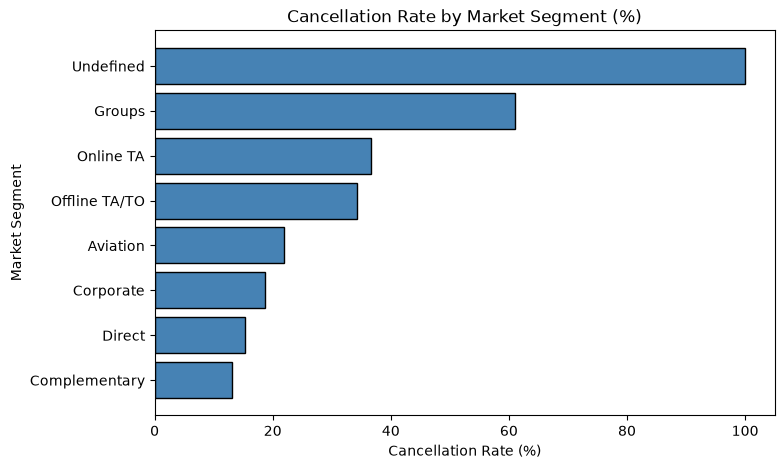

In [5]:
segment_cancel = (df.groupby('market_segment')['is_canceled'].mean() * 100).sort_values()
print(segment_cancel.round(2))

plt.figure(figsize=(8, 5))
plt.barh(segment_cancel.index, segment_cancel.values, color='steelblue', edgecolor='black')
plt.title('Cancellation Rate by Market Segment (%)')
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Market Segment')
plt.show()


### 5. Cancellation Rate by Deposit Type
Examine how deposit terms relate to cancellations.


deposit_type
No Deposit    28.38
Non Refund    99.36
Refundable    22.22
Name: is_canceled, dtype: float64


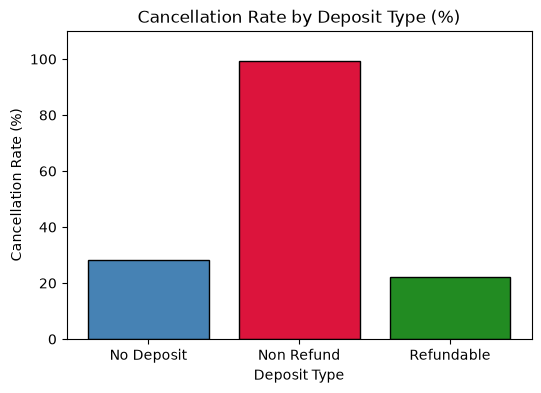

In [6]:
deposit_cancel = df.groupby('deposit_type')['is_canceled'].mean() * 100
print(deposit_cancel.round(2))

plt.figure(figsize=(6, 4))
plt.bar(deposit_cancel.index, deposit_cancel.values, color=['steelblue', 'crimson', 'forestgreen'], edgecolor='black')
plt.title('Cancellation Rate by Deposit Type (%)')
plt.xlabel('Deposit Type')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 110)
plt.show()


### 6. Cancellation Rate by Special Requests
Test whether making special requests associates with lower cancellation.


total_of_special_requests
0    47.72
1    22.02
2    22.10
3    17.86
4    10.59
5     5.00
Name: is_canceled, dtype: float64


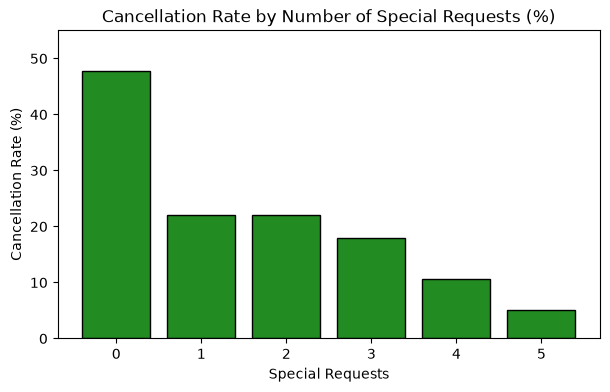

In [7]:
request_cancel = df.groupby('total_of_special_requests')['is_canceled'].mean() * 100
print(request_cancel.round(2))

plt.figure(figsize=(7, 4))
plt.bar(request_cancel.index.astype(str), request_cancel.values, color='forestgreen', edgecolor='black')
plt.title('Cancellation Rate by Number of Special Requests (%)')
plt.xlabel('Special Requests')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 55)
plt.show()


### 7. Lead Time Distribution
Distribution shape of booking lead time (days).


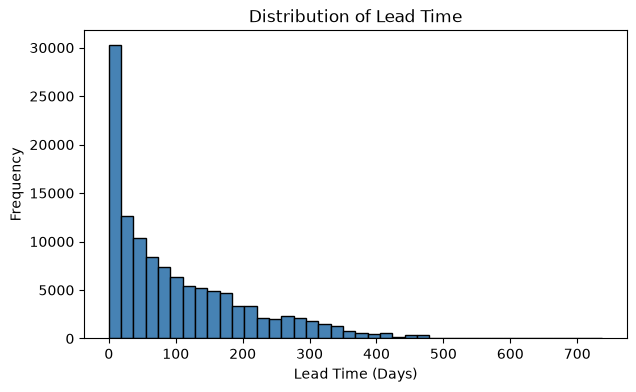

In [8]:
plt.figure(figsize=(7, 4))
plt.hist(df['lead_time'], bins=40, color='steelblue', edgecolor='black')
plt.title('Distribution of Lead Time')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Frequency')
plt.show()


### 8. ADR Distribution (Average Daily Rate)
Distribution of room rates (filtered to standard rates <= $400 to remove the $5,400 outlier).


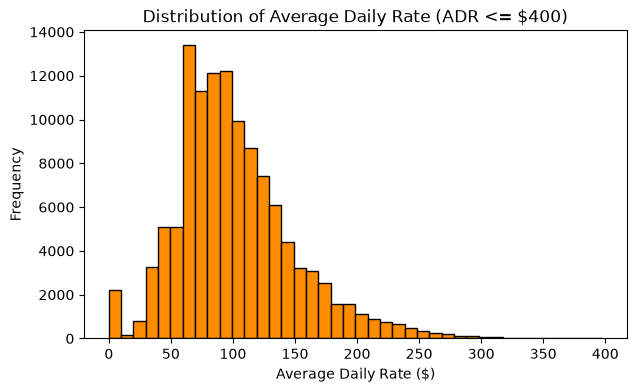

In [9]:
normal_adr = df[(df['adr'] >= 0) & (df['adr'] <= 400)]['adr']

plt.figure(figsize=(7, 4))
plt.hist(normal_adr, bins=40, color='darkorange', edgecolor='black')
plt.title('Distribution of Average Daily Rate (ADR <= $400)')
plt.xlabel('Average Daily Rate ($)')
plt.ylabel('Frequency')
plt.show()


### 9. Correlation Matrix with `is_canceled`
Check linear correlations among key numerical features.


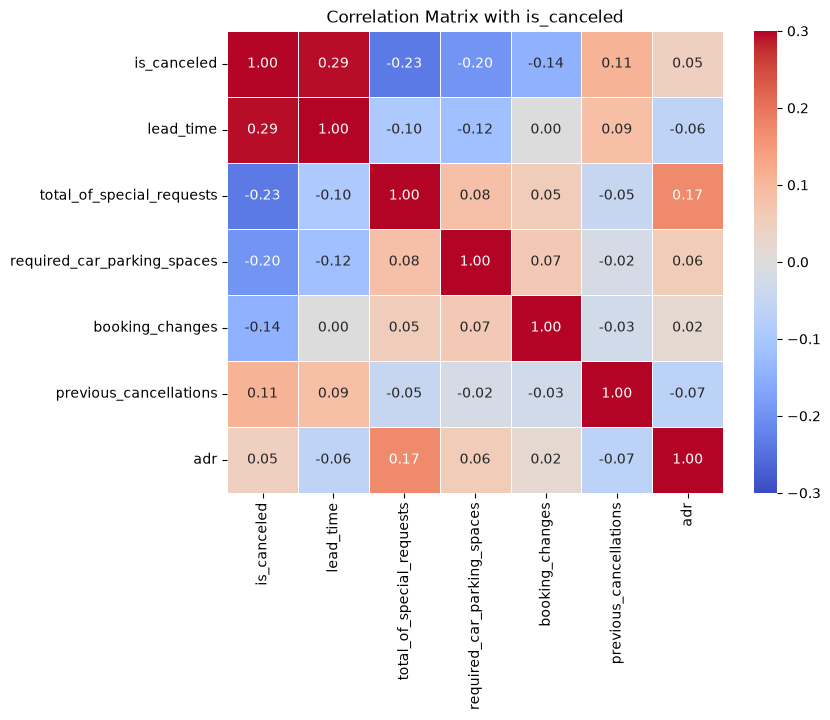

In [10]:
key_features = [
    'is_canceled', 'lead_time', 'total_of_special_requests',
    'required_car_parking_spaces', 'booking_changes',
    'previous_cancellations', 'adr'
]

corr = df[key_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.3, vmax=0.3, linewidths=0.5)
plt.title('Correlation Matrix with is_canceled')
plt.show()


### 10. Key Takeaways for Modeling

1. **Lead Time:** Longer lead times increase cancellation rates (from ~11% to >55%).
2. **Hotel Property:** City Hotels experience higher cancellations (41.7%) than Resort Hotels (27.8%).
3. **Market Segment:** Groups (61.1%) and Online TAs (36.7%) cancel much more often than Direct bookings (15.3%).
4. **Special Requests:** More requests correlate with fewer cancellations (<18% for 2+ requests).
5. **Deposit Type:** Non-refundable bookings have a ~99% cancellation rate in this dataset (group tour bookings).
6. **Leakage Warning:** `reservation_status` and `reservation_status_date` must be dropped before training.
